# Merged HMM: PCA persistence and performance diagnostics

Read-only analysis of merged signals, displaying PCA branches only. Final-model transition diagnostics load the original trusted checkpoints referenced by the merge manifest. Never load untrusted pickle files.

Final transition matrices describe the latest saved models, not historical paths. Signals are decision-date forecasts for the next trading day. Performance is price-only, without dividends, interest, or trading costs. Historical emission replay is not performed in this merged view: the older replay helpers assume the original model set and do not support the additional GMM3 branch.


In [1]:
%matplotlib inline
from pathlib import Path
import pickle
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents]
            if (path / "data/processed/sp500_index_price.csv").exists())
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT / "notebooks/sp500"))
from paper_regime_experiment import evaluate_signals
from model_evaluation.market_strategy.evaluation import compare_strategies

RESULT_DIR = ROOT / "notebooks/sp500/results/merged_regime_2004_2025"
fits = pd.read_csv(RESULT_DIR / "signals.csv", parse_dates=["date"])
fits = fits.loc[fits["pca"].eq(True)].copy()
if fits.empty or fits.duplicated(["date", "model", "pca"]).any():
    raise ValueError("Missing or duplicated PCA signals")
coverage = fits.pivot(index="date", columns="model", values="bull_probability")
if coverage.isna().any().any():
    raise ValueError("PCA branches must share all decision dates")

# Resolve original checkpoint files from merge provenance.
import json
manifest = json.loads((RESULT_DIR / "manifest.json").read_text())
branches = {}
for source in manifest["sources"]:
    checkpoint_path = ROOT / source["checkpoint"]
    with checkpoint_path.open("rb") as handle:
        saved = pickle.load(handle)
    if pd.Timestamp(saved["last_date"]) != fits.date.max():
        raise ValueError("Source checkpoint and merged signals end on different dates")
    for branch_key, bundle in saved["branches"].items():
        model, scaler, pca = bundle
        if pca is None:
            continue
        if isinstance(branch_key, tuple):
            name = branch_key[0]
        else:
            name = "GMM" if branch_key.startswith("gmm") else branch_key
        if name == "GMM":
            name = f"GMM (M={model.emission.n_components})"
        if (name, True) in branches:
            raise ValueError(f"Duplicate checkpoint branch: {name}")
        branches[(name, True)] = bundle
state = {"last_date": fits.date.max(), "branches": branches}
if set(branches) != set(zip(fits.model, fits.pca)):
    raise ValueError("Checkpoint branches do not match merged PCA signals")
prices = (pd.read_csv(ROOT / "data/processed/sp500_index_price.csv",
                      parse_dates=["YYYYMMDD"])
          .set_index("YYYYMMDD")["DlyPrcInd"].astype(float).sort_index())
next_return = prices.pct_change(fill_method=None).shift(-1).reindex(
    pd.DatetimeIndex(fits.date.unique()).sort_values()
)
if next_return.isna().any():
    raise ValueError("A decision has no next-day price return")
print(f"Checkpoint through {state['last_date'].date()}: "
      f"{fits.date.nunique()} decisions, "
      f"{fits.loc[fits.refresh, 'date'].nunique()} fresh-fit dates")
print("The saved transition matrices belong to the LAST completed day's models.")


Checkpoint through 2025-12-30: 5534 decisions, 88 fresh-fit dates
The saved transition matrices belong to the LAST completed day's models.


In [2]:
from paper_regime_experiment import build_observations, label_bull
from run_paper_regime import HALF_LIVES, WINDOWS

features = build_observations(prices, windows=WINDOWS,
                              half_lives=HALF_LIVES).dropna()
initial_days = int(fits.loc[fits.date.eq(fits.date.min()),
                            "training_days"].iloc[0])
initial_end = features.index.get_loc(fits.date.min())
first_training_date = features.index[initial_end - initial_days + 1]
history = features.loc[first_training_date:state["last_date"]]
if len(history) != int(fits.loc[fits.date.eq(state["last_date"]),
                           "training_days"].iloc[0]):
    raise ValueError("Saved training window does not match reconstructed features")
history_returns = prices.pct_change(fill_method=None).reindex(history.index).to_numpy()
rows = []
for (name, use_pca), (model, scaler, pca) in state["branches"].items():
    X = scaler.transform(history)
    if pca is not None:
        X = pca.transform(X)
    bull = label_bull(model, X, history_returns)
    P = model.states.transitions
    key = f"{name} / {'PCA' if use_pca else 'no PCA'}"
    for label, index in (("bull", bull), ("bear", 1 - bull)):
        stay = float(P[index, index])
        rows.append({"model": key, "state": label, "state_index": index,
                     "P(stay)": stay,
                     "implied_days": 1 / (1 - stay) if stay < 1 else np.inf,
                     "components": X.shape[1]})
transition_table = pd.DataFrame(rows).set_index(["model", "state"])
display(transition_table.round(3))


state_index  P(stay)  implied_days  components
model           state                                                
Gaussian / PCA  bull             0    0.995       183.061          11
                bear             1    0.942        17.198          11
GMM (M=2) / PCA bull             0    0.956        22.602          11
                bear             1    0.988        86.764          11
Student-t / PCA bull             0    0.979        47.562          11
                bear             1    0.979        47.759          11
GMM (M=3) / PCA bull             1    0.977        44.082          11
                bear             0    0.975        40.380          11

,raw bull %,invested %,raw switches/year,position switches/year,median raw run,median position run,mean position run
model,,,,,,,
GMM (M=2) / PCA,36.94,36.70,9.70,4.87,13.0,30.5,51.24
GMM (M=3) / PCA,55.67,55.66,9.38,4.46,14.0,38.0,55.90
Gaussian / PCA,21.49,19.55,9.88,3.32,7.0,25.0,74.78
Student-t / PCA,45.55,45.59,6.56,5.01,25.0,30.0,49.86


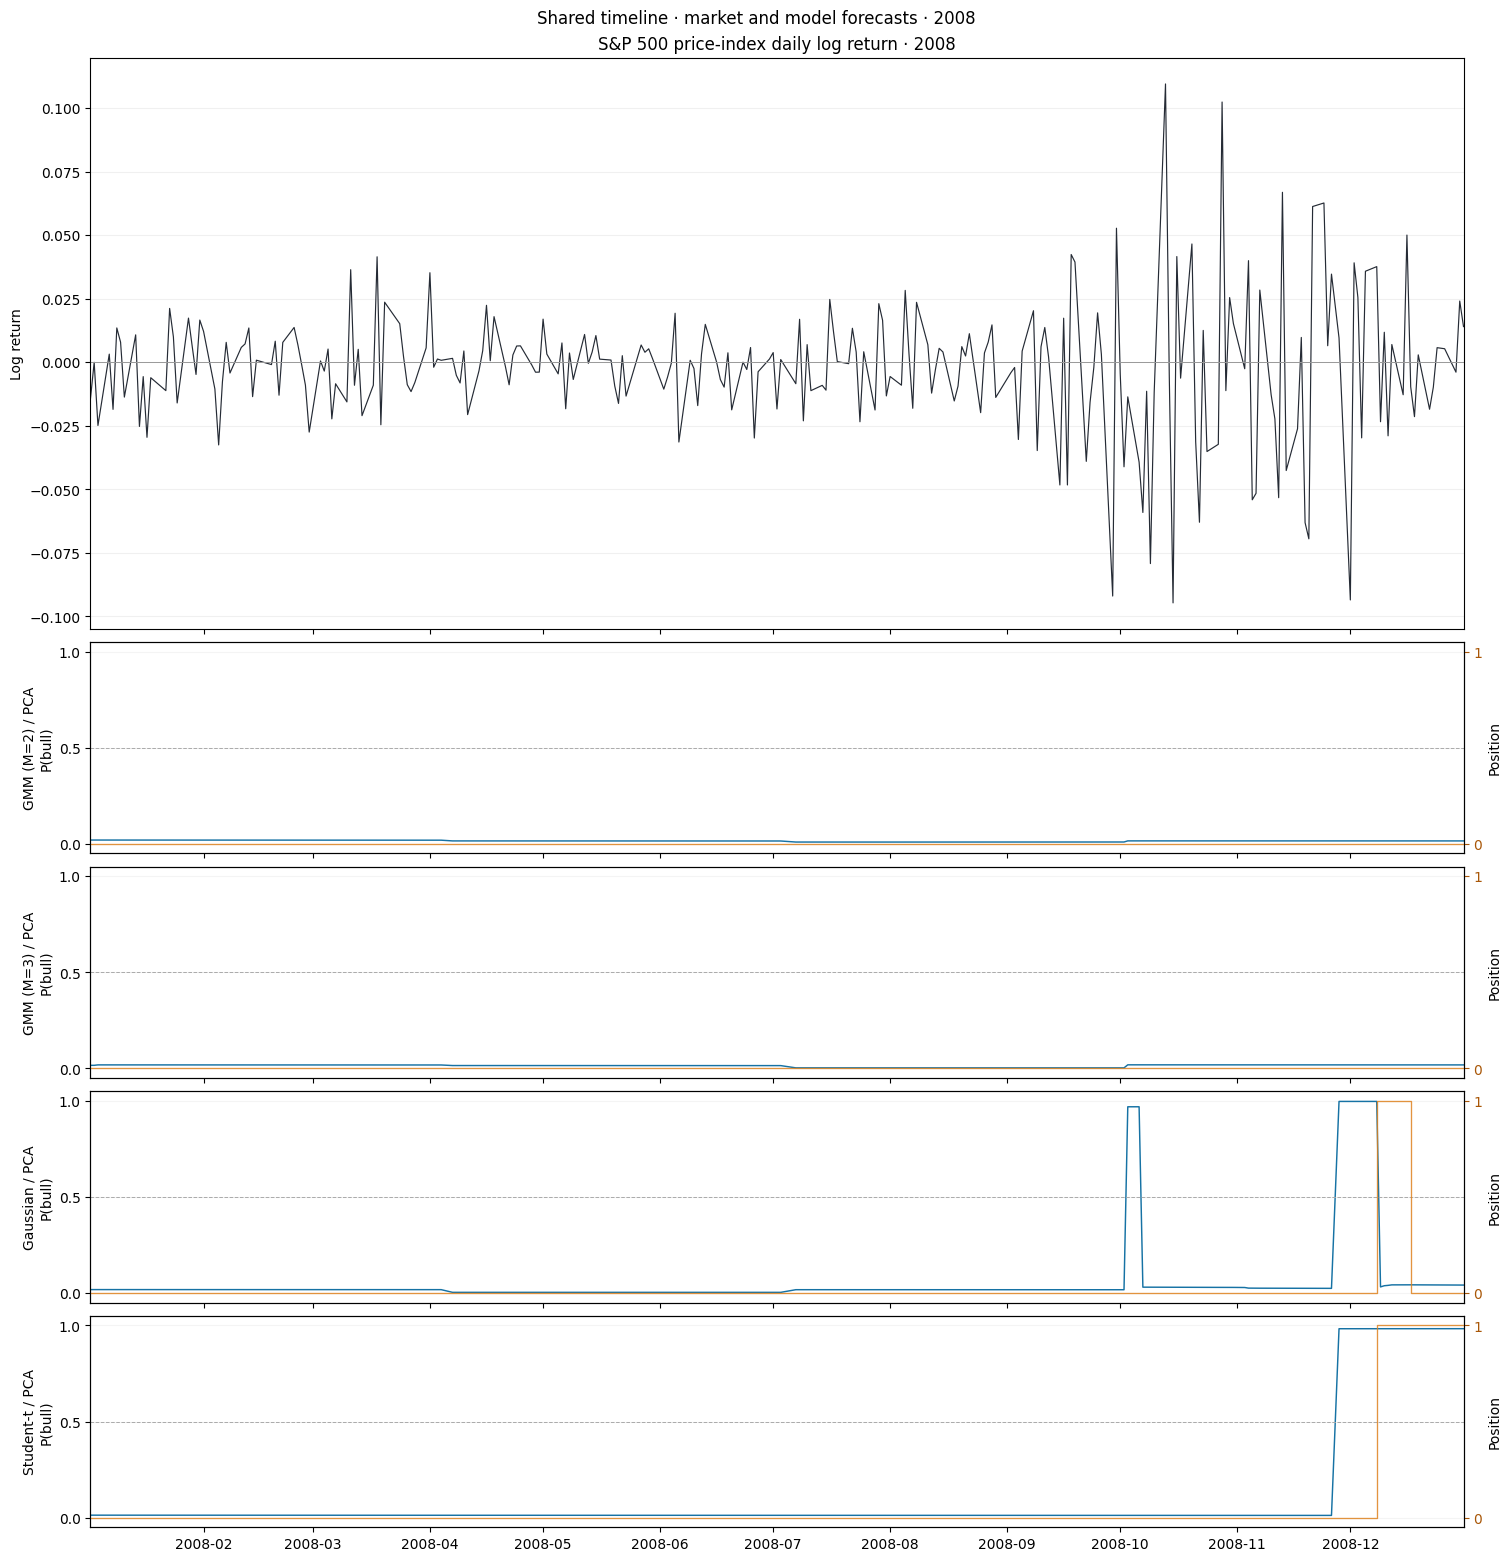

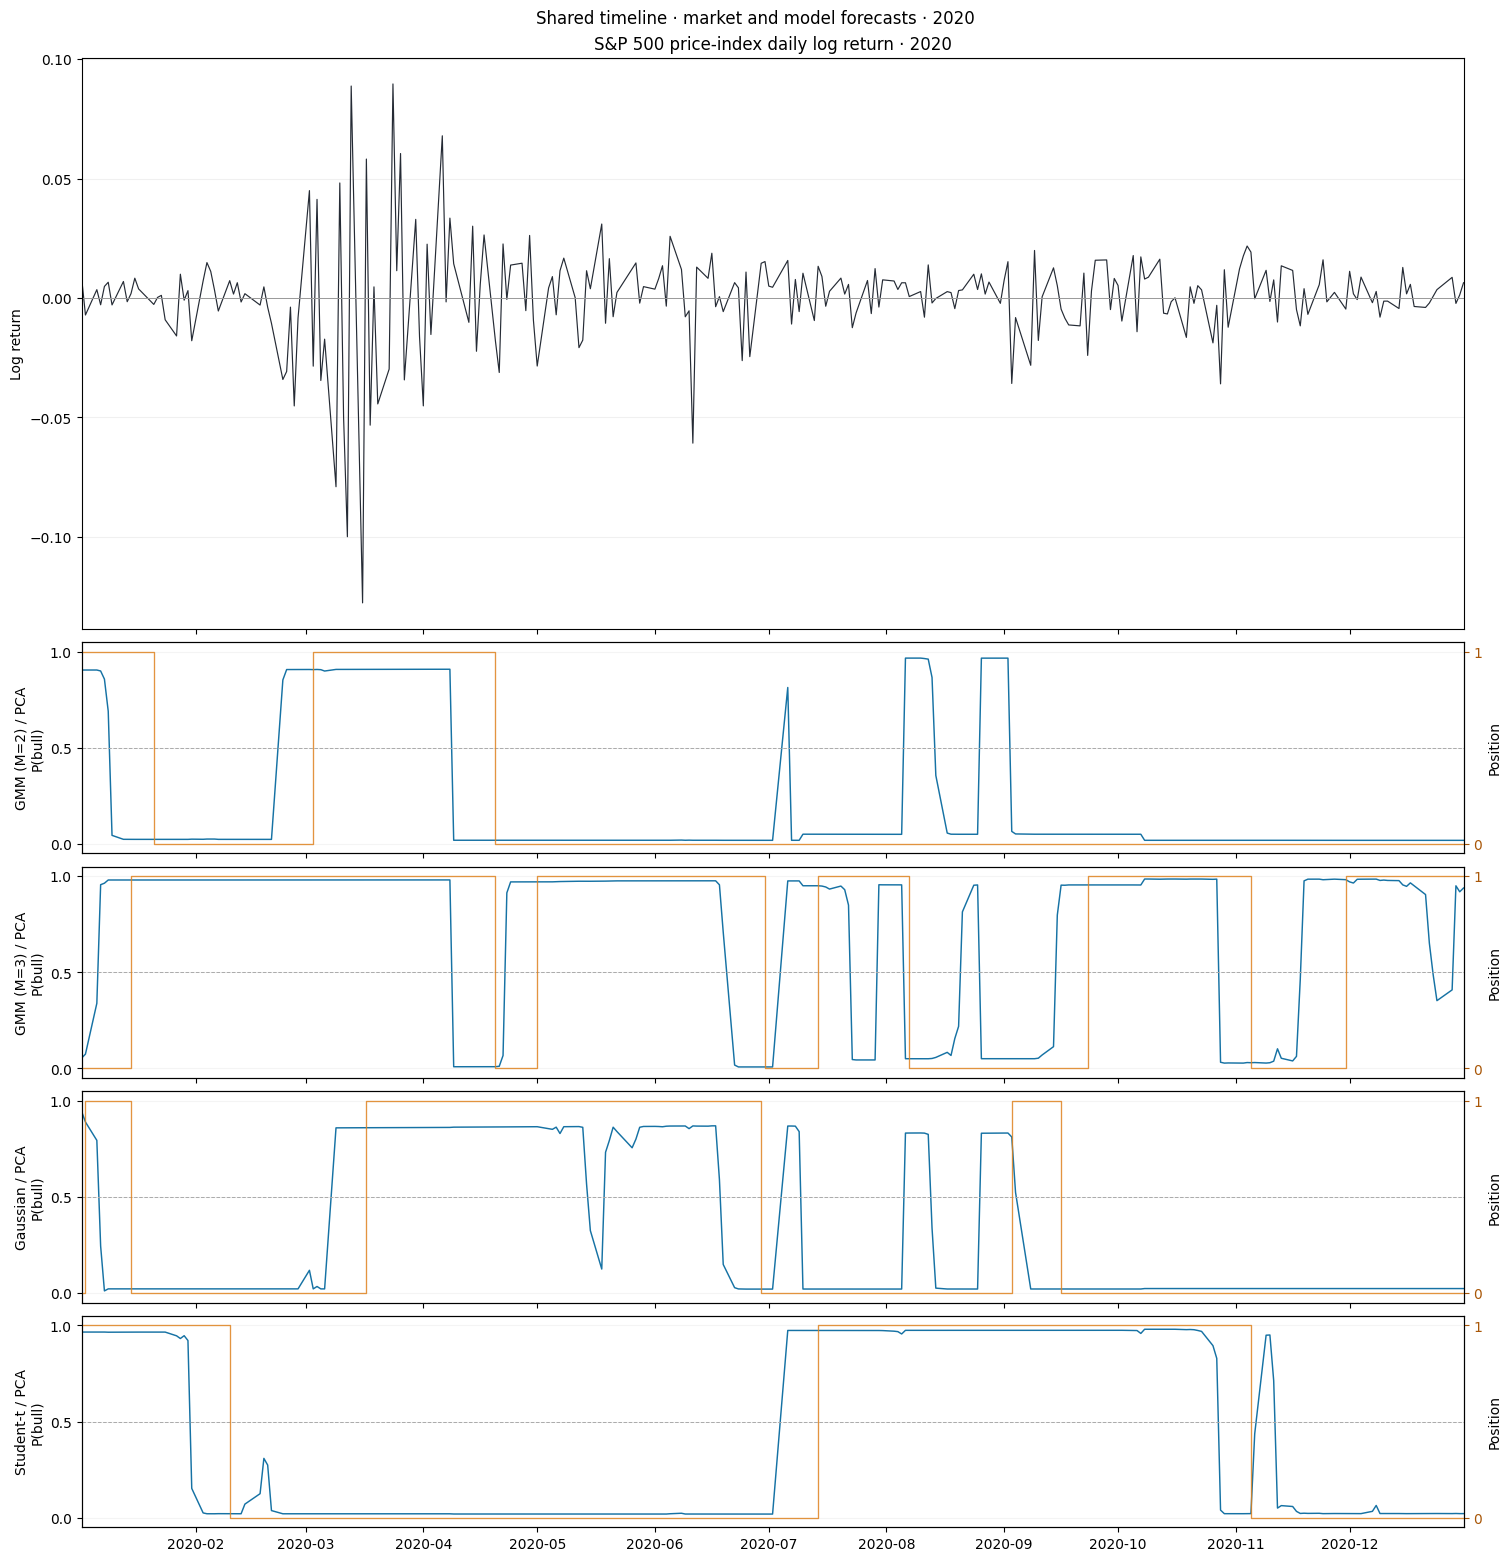

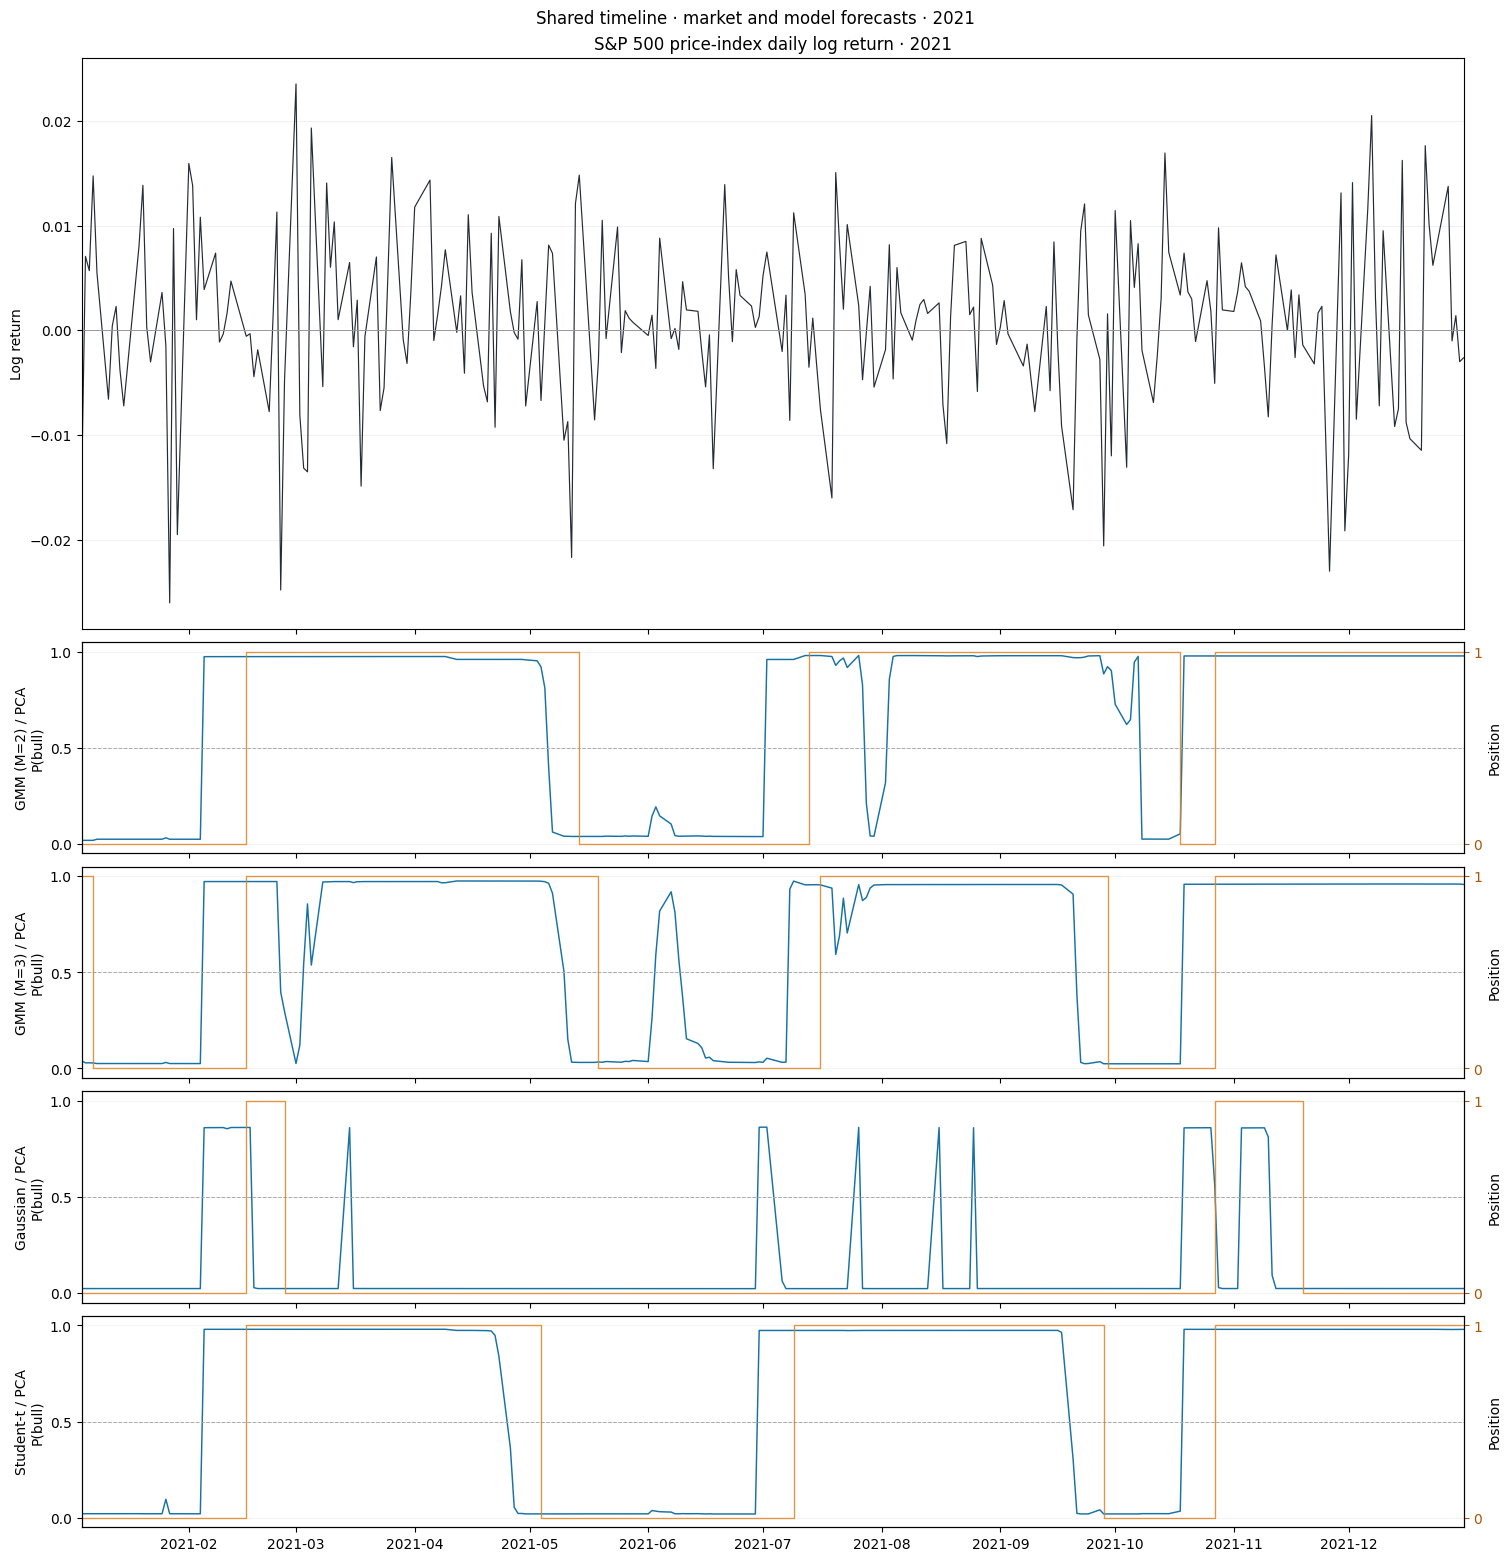

In [3]:
pnl, weights = evaluate_signals(fits, prices, median_window=12)

def run_lengths(values):
    values = np.asarray(values)
    boundaries = np.r_[0, np.flatnonzero(np.diff(values)) + 1, len(values)]
    return np.diff(boundaries)

rows = []
for (name, use_pca), group in fits.groupby(["model", "pca"]):
    key = f"{name} / {'PCA' if use_pca else 'no PCA'}"
    raw = group.sort_values("date")["bull_raw"].to_numpy()
    exposure = weights[key].to_numpy()
    raw_runs, exposure_runs = run_lengths(raw), run_lengths(exposure)
    rows.append({"model": key, "raw bull %": raw.mean() * 100,
                 "invested %": exposure.mean() * 100,
                 "raw switches/year": (len(raw_runs) - 1) * 252 / len(raw),
                 "position switches/year": (len(exposure_runs) - 1) * 252 / len(raw),
                 "median raw run": np.median(raw_runs),
                 "median position run": np.median(exposure_runs),
                 "mean position run": np.mean(exposure_runs)})
persistence = pd.DataFrame(rows).set_index("model")
display(persistence.round(2))
# Compute exposures on the complete series before selecting calendar years.
plot_years = (2008, 2020, 2021)
branches = list(fits.groupby(["model", "pca"], sort=True))


def plot_market(ax, returns, year):
    """Plot the price-index log return as a shared market reference."""
    ax.plot(returns.index, returns, color="#252b35", lw=0.85)
    ax.axhline(0, color="#999", lw=0.7)
    ax.set(title=f"S&P 500 price-index daily log return · {year}",
           ylabel="Log return")
    ax.grid(axis="y", alpha=0.18)


def plot_branch(ax, key, group):
    """Plot one branch's decision-date forecast and filtered position."""
    dates = group["date"]
    ax.plot(dates, group["bull_probability"], color="#1672a4", lw=1.05)
    ax.axhline(0.5, color="#aaa", ls="--", lw=0.7)
    ax.set(ylabel=f"{key}\nP(bull)", ylim=(-0.05, 1.05),
           yticks=[0, 0.5, 1])
    ax.grid(axis="y", alpha=0.13)
    position_ax = ax.twinx()
    position_ax.step(dates, weights[key].reindex(dates), where="post",
                     color="#de821e", lw=0.95, alpha=0.85)
    position_ax.set(ylim=(-0.05, 1.05), yticks=[0, 1], ylabel="Position")
    position_ax.tick_params(axis="y", colors="#a95708")


for year in plot_years:
    year_groups = [
        (name, use_pca, group.loc[group.date.dt.year.eq(year)])
        for (name, use_pca), group in branches
    ]
    if not any(not group.empty for _, _, group in year_groups):
        print(f"{year}: no saved decisions; skipped.")
        continue
    market_returns = np.log(prices).diff().loc[f"{year}-01-01":f"{year}-12-31"]
    fig, axes = plt.subplots(
        1 + len(year_groups), 1, figsize=(15, 15.5), sharex=True,
        gridspec_kw={"height_ratios": [2.7] + [1] * len(year_groups)},
        layout="constrained",
    )
    plot_market(axes[0], market_returns, year)
    for ax, (name, use_pca, group) in zip(axes[1:], year_groups):
        key = f"{name} / {'PCA' if use_pca else 'no PCA'}"
        if group.empty:
            ax.set_axis_off()
            continue
        plot_branch(ax, key, group)
    axes[-1].set_xlim(market_returns.index[0], market_returns.index[-1])
    fig.suptitle(f"Shared timeline · market and model forecasts · {year}")
    plt.show()

,total_return,sharpe,max_drawdown,exposure,turnover_per_year
Student-t / PCA,2.517,0.640,-0.214,0.456,5.009
GMM (M=3) / PCA,3.796,0.544,-0.339,0.557,4.463
Buy and hold,5.176,0.439,-0.568,1.000,0.000
GMM (M=2) / PCA,1.386,0.356,-0.292,0.367,4.872
Gaussian / PCA,0.606,0.243,-0.239,0.196,3.324


,cash on up days %,cash on down days %,"avoided losses, log pp","missed gains, log pp","net log advantage, pp"
model,,,,,
GMM (M=2) / PCA,63.00,63.68,1331.93,1427.00,-95.08
GMM (M=3) / PCA,43.62,45.22,1003.02,1028.30,-25.28
Gaussian / PCA,80.19,80.74,1600.77,1735.46,-134.69
Student-t / PCA,53.64,55.34,1343.60,1399.90,-56.29


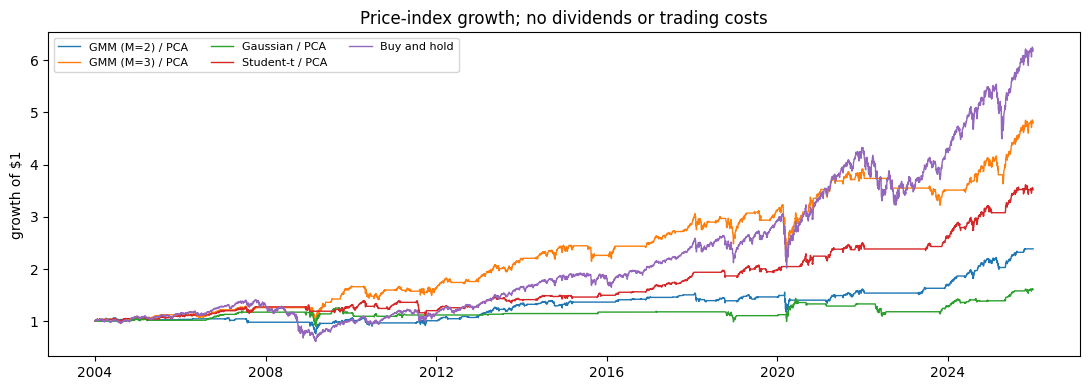

In [4]:
summary = compare_strategies(pnl, weights)
display(summary[["total_return", "sharpe", "max_drawdown", "exposure",
                 "turnover_per_year"]].round(3))

attribution = []
for key, exposure in weights.items():
    if key == "Buy and hold":
        continue
    r = next_return.reindex(exposure.index)
    cash = exposure.eq(0)
    cash_up = cash & r.gt(0)
    cash_down = cash & r.lt(0)
    advantage = pnl[key] - pnl["Buy and hold"]
    attribution.append({
        "model": key,
        "cash on up days %": 100 * cash_up.sum() / r.gt(0).sum(),
        "cash on down days %": 100 * cash_down.sum() / r.lt(0).sum(),
        "avoided losses, log pp": -100 * np.log1p(r[cash_down]).sum(),
        "missed gains, log pp": 100 * np.log1p(r[cash_up]).sum(),
        "net log advantage, pp": 100 * advantage.sum(),
    })
attribution = pd.DataFrame(attribution).set_index("model")
assert np.allclose(attribution["net log advantage, pp"],
                   attribution["avoided losses, log pp"]
                   - attribution["missed gains, log pp"])
display(attribution.round(2))
fig, ax = plt.subplots(figsize=(11, 4))
for key in pnl:
    ax.plot(pnl[key].index, np.exp(pnl[key].cumsum()), lw=1, label=key)
ax.set(title="Price-index growth; no dividends or trading costs", ylabel="growth of $1")
ax.legend(ncol=3, fontsize=8)
fig.tight_layout()
plt.show()


In [5]:
forecast_rows = []
annual_rows = []
for (name, use_pca), group in fits.groupby(["model", "pca"]):
    key = f"{name} / {'PCA' if use_pca else 'no PCA'}"
    group = group.sort_values("date").set_index("date")
    r = next_return.reindex(group.index)
    exposure = weights[key].reindex(group.index)
    forecast_rows.append({"model": key, "bull forecast days": int(group.bull_raw.sum()),
                          "bear forecast days": int((1 - group.bull_raw).sum()),
                          "next-day return | bull %": 100 * r[group.bull_raw.eq(1)].mean(),
                          "next-day return | bear %": 100 * r[group.bull_raw.eq(0)].mean(),
                          "next-day return | invested %": 100 * r[exposure.eq(1)].mean(),
                          "next-day return | cash %": 100 * r[exposure.eq(0)].mean()})
    yearly = (pnl[key] - pnl["Buy and hold"]).groupby(group.index.year).agg(
        ["count", "sum"]
    )
    for year, values in yearly.iterrows():
        annual_rows.append({"year": year, "model": key, "days": int(values["count"]),
                            "log advantage, pp": 100 * values["sum"]})
display(pd.DataFrame(forecast_rows).set_index("model").round(4))
annual = pd.DataFrame(annual_rows)
display(annual.pivot(index=["year", "days"], columns="model",
                     values="log advantage, pp").round(2))


,bull forecast days,bear forecast days,next-day return | bull %,next-day return | bear %,next-day return | invested %,next-day return | cash %
model,,,,,,
GMM (M=2) / PCA,2044,3490,0.0343,0.0433,0.0495,0.0344
GMM (M=3) / PCA,3081,2453,0.0581,0.0171,0.0570,0.0186
Gaussian / PCA,1189,4345,0.0441,0.0388,0.0518,0.0371
Student-t / PCA,2521,3013,0.0550,0.0274,0.0533,0.0288


,model,GMM (M=2) / PCA,GMM (M=3) / PCA,Gaussian / PCA,Student-t / PCA
year,days,,,,
2004,252,-2.69,-1.84,-3.97,0.04
2005,252,-7.40,-0.02,-7.78,-3.99
2006,251,-9.97,-3.29,-1.41,-3.20
2007,251,-8.55,1.63,2.50,4.80
2008,253,44.02,44.02,43.44,46.42
2009,252,-13.12,7.78,-20.48,-20.06
2010,252,-19.33,-15.22,-16.97,-9.86
2011,252,3.77,2.51,1.78,-9.88
2012,250,-3.85,-3.03,-13.55,-4.31


## Next-day return separation by forecast and position

For each branch, compare mean **next-day S&P 500 price-index simple returns** on days forecast bull versus bear, and on days positioned invested versus cash. Each cell is the first conditional mean minus the second, displayed as a difference in %-valued daily returns (not a relative percentage improvement). The bull forecast uses $P(\text{bull}) \geq 0.5$; the invested/cash position uses the trailing 12-decision-day median, computed on the full sequence before any date selection. A decision made using prices through day $t$ is paired with the price return from $t$ to the next trading day. These are descriptive full-period associations, not a statistical significance test or a held-out model-selection claim.


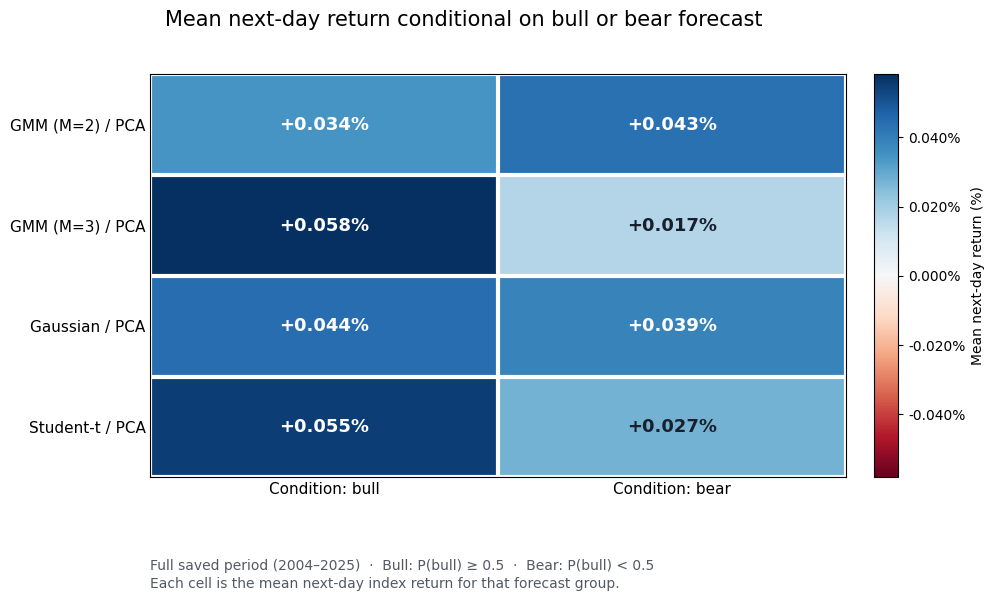

In [6]:
from matplotlib.colors import TwoSlopeNorm

comparison = pd.DataFrame(forecast_rows).set_index("model")
labels = comparison.index.tolist()

conditional_returns = comparison[[
    "next-day return | bull %",
    "next-day return | bear %",
]].rename(columns={
    "next-day return | bull %": "Condition: bull",
    "next-day return | bear %": "Condition: bear",
})

values = conditional_returns.to_numpy()
finite_values = values[np.isfinite(values)]
if finite_values.size == 0:
    raise ValueError("No finite conditional returns to display")

limit = max(float(np.max(np.abs(finite_values))), 1e-6)

fig, ax = plt.subplots(figsize=(11.4, 6.15))
fig.subplots_adjust(left=.225, right=.835, top=.86, bottom=.205)

heat = ax.imshow(
    np.ma.masked_invalid(values),
    cmap="RdBu",
    aspect="auto",
    norm=TwoSlopeNorm(vmin=-limit, vcenter=0, vmax=limit),
)

ax.set_xticks((0, 1), conditional_returns.columns, fontsize=11)
ax.set_yticks(range(len(labels)), labels, fontsize=11)
ax.tick_params(length=0)
ax.set_xticks(np.arange(-.5, 2, 1), minor=True)
ax.set_yticks(np.arange(-.5, len(labels), 1), minor=True)
ax.grid(which="minor", color="white", linewidth=3)
ax.tick_params(which="minor", bottom=False, left=False)

for row in range(len(labels)):
    for col in range(2):
        value = values[row, col]
        ax.text(
            col, row,
            f"{value:+.3f}%" if np.isfinite(value) else "N/A",
            ha="center",
            va="center",
            fontsize=13,
            fontweight="semibold",
            color=(
                "white"
                if np.isfinite(value) and abs(value) > .55 * limit
                else "#18202c"
            ),
        )

cax = fig.add_axes([.86, .205, .021, .655])
fig.colorbar(
    heat,
    cax=cax,
    format="%.3f%%",
    label="Mean next-day return (%)",
)

fig.suptitle(
    "Mean next-day return conditional on bull or bear forecast",
    fontsize=15,
    y=.965,
)
fig.text(
    .225, .055,
    "Full saved period (2004–2025)  ·  "
    "Bull: P(bull) ≥ 0.5  ·  Bear: P(bull) < 0.5",
    fontsize=10,
    color="#535963",
)
fig.text(
    .225, .025,
    "Each cell is the mean next-day index return for that forecast group.",
    fontsize=10,
    color="#535963",
)

plt.show()

## Year-by-year return separation

The full-period heatmap can conceal a result concentrated in a few years. Recalculate both differences **within each calendar year**, using the same saved next-day simple returns and full-history 12-day median positions as above. Values are differences between mean daily returns in `%` units, not annual strategy returns. A missing group is reported as `NaN`, not zero; group counts for the Student-t PCA branch accompany the differences. Yearly observations and overlapping regimes are not independent significance tests.


In [7]:
yearly_rows = []
for (name, use_pca), group in fits.groupby(["model", "pca"]):
    key = f"{name} / {'PCA' if use_pca else 'no PCA'}"
    group = group.sort_values("date").set_index("date")
    for year, portion in group.groupby(group.index.year):
        r = next_return.reindex(portion.index)
        bull = portion["bull_raw"].eq(1)
        invested = weights[key].reindex(portion.index).eq(1)

        def difference(mask):
            return 100 * (r[mask].mean() - r[~mask].mean()) if mask.any() and (~mask).any() else np.nan

        yearly_rows.append({
            "year": year, "model": key, "days": len(portion),
            "bull − bear %": difference(bull),
            "invested − cash %": difference(invested),
            "bull days": int(bull.sum()), "bear days": int((~bull).sum()),
            "invested days": int(invested.sum()), "cash days": int((~invested).sum()),
        })
yearly_separation = pd.DataFrame(yearly_rows).set_index(["year", "model"])
for measure in ("bull − bear %", "invested − cash %"):
    print(f"Yearly mean next-day return difference: {measure}")
    print(yearly_separation[measure].unstack("model")[labels].round(3).to_string())

print("Student-t PCA group sizes by year")
t_rows = yearly_separation.loc[(slice(None), ["Student-t / PCA"]), :]
display(t_rows[["days", "bull days", "bear days", "invested days", "cash days"]])

Yearly mean next-day return difference: bull − bear %
model  GMM (M=2) / PCA  GMM (M=3) / PCA  Gaussian / PCA  Student-t / PCA
year                                                                    
2004             0.136            0.029           0.090            0.079
2005            -0.077           -0.001          -0.029           -0.094
2006            -0.087           -0.198           0.034           -0.013
2007            -0.144            0.109          -0.081            0.085
2008               NaN              NaN          -0.972            0.392
2009            -0.137           -0.097          -0.084           -0.030
2010            -0.337           -0.017           0.152           -0.012
2011            -0.189            0.249           0.039           -0.162
2012             0.148            0.091          -0.180            0.082
2013            -0.201           -0.157           0.035           -0.123
2014            -0.041            0.060          -0.022           -0.0

,,days,bull days,bear days,invested days,cash days
year,model,,,,,
2004,Student-t / PCA,252,119,133,116,136
2005,Student-t / PCA,252,115,137,116,136
2006,Student-t / PCA,251,128,123,128,123
2007,Student-t / PCA,251,130,121,136,115
2008,Student-t / PCA,253,23,230,17,236
2009,Student-t / PCA,252,99,153,101,151
2010,Student-t / PCA,252,158,94,164,88
2011,Student-t / PCA,252,75,177,77,175
2012,Student-t / PCA,250,117,133,115,135


## Student-t PCA forecasts and index level in 2008

Saved decision-date PCA forecasts above the S&P 500 price index. The threshold is 0.5; forecasts refer to the next trading day.

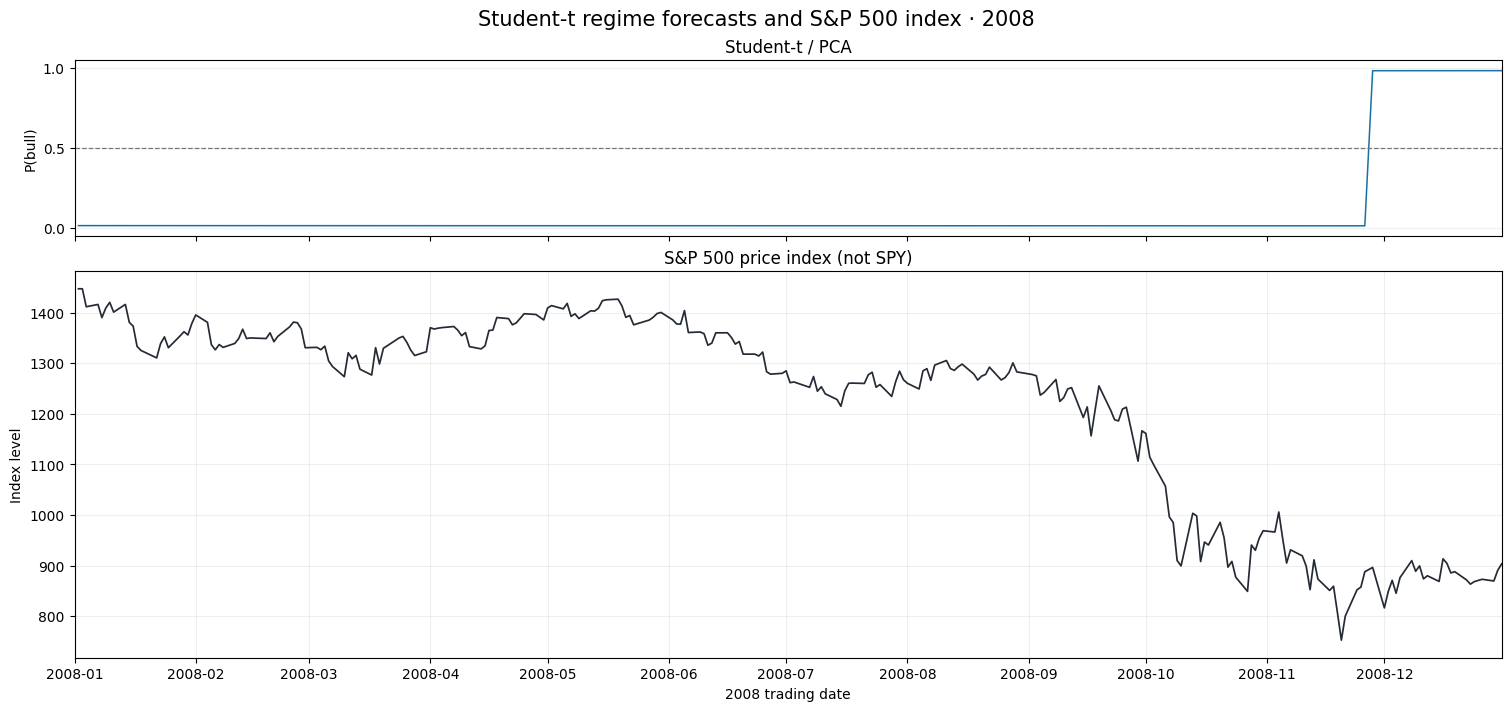

In [8]:
year_start = pd.Timestamp("2008-01-01")
year_end = pd.Timestamp("2008-12-31")
market_2008 = prices.loc[year_start:year_end]
if market_2008.empty:
    raise ValueError("The price series does not contain 2008")

fig, axes = plt.subplots(
    2, 1, figsize=(15, 7), sharex=True,
    gridspec_kw={"height_ratios": [1, 2.2]}, layout="constrained",
)
for ax, use_pca, title in zip(
    axes[:1], (True,), ("Student-t / PCA",)
):
    group = fits.loc[
        fits.model.eq("Student-t") & fits.pca.eq(use_pca)
        & fits.date.between(year_start, year_end)
    ].sort_values("date")
    if group.empty:
        raise ValueError(f"No saved 2008 forecasts for {title}")
    ax.plot(group.date, group.bull_probability, color="#1672a4", lw=1.1)
    ax.axhline(0.5, color="#777", linestyle="--", linewidth=0.9)
    ax.set(ylabel="P(bull)", ylim=(-0.05, 1.05), yticks=[0, 0.5, 1],
           title=title)
    ax.grid(axis="y", alpha=0.2)

axes[1].plot(market_2008.index, market_2008, color="#252b35", lw=1.25)
axes[1].set(title="S&P 500 price index (not SPY)", ylabel="Index level",
            xlabel="2008 trading date", xlim=(year_start, year_end))
axes[1].grid(alpha=0.2)
fig.suptitle("Student-t regime forecasts and S&P 500 index · 2008", fontsize=15)
plt.show()


## Year-by-year strategy Sharpe variability

For each calendar year and branch, compute the annualized Sharpe of the **next-day, 0/1, 12-day median-smoothed strategy log PnL** used above: `sqrt(252) * daily_mean / daily_sample_std`, with zero risk-free rate, no dividends, financing or trading costs. Then report the unweighted mean and sample standard deviation of those **yearly Sharpe ratios** (not the standard deviation of daily returns or uncertainty of the mean). A year with no daily PnL variation has an undefined Sharpe and is excluded from the mean/SD; its count is shown. In particular, a cash-only year is *not* assigned a Sharpe of zero. The 2008 column and mean without 2008 help assess dependence on that year; these descriptive comparisons are not a significance test.


In [9]:
yearly_sharpe = {}
for name, log_pnl in pnl.items():
    yearly_sharpe[name] = {}
    for year, daily in log_pnl.groupby(log_pnl.index.year):
        daily = daily.dropna()
        volatility = daily.std(ddof=1)
        yearly_sharpe[name][year] = (
            np.sqrt(252) * daily.mean() / volatility
            if len(daily) >= 2 and np.isfinite(volatility) and volatility > 0
            else np.nan
        )
yearly_sharpe = pd.DataFrame(yearly_sharpe).sort_index()

sharpe_summary = pd.DataFrame({
    "avg yearly Sharpe": yearly_sharpe.mean(),
    "std yearly Sharpe": yearly_sharpe.std(ddof=1),
    "valid years": yearly_sharpe.count(),
    "undefined years": yearly_sharpe.isna().sum(),
    "2008 Sharpe": yearly_sharpe.loc[2008],
    "avg excluding 2008": yearly_sharpe.drop(index=2008).mean(),
}).loc[labels + ["Buy and hold"]]
print("Annualized Sharpe in each calendar year (NaN = zero daily variation):")
print(yearly_sharpe[labels + ["Buy and hold"]].round(3).to_string())
print("\nYearly Sharpe summary (equal weighting across defined years):")
print(sharpe_summary.round(3).to_string())


Annualized Sharpe in each calendar year (NaN = zero daily variation):
      GMM (M=2) / PCA  GMM (M=3) / PCA  Gaussian / PCA  Student-t / PCA  Buy and hold
2004            0.973            0.815           0.627            1.197         0.729
2005           -0.478            0.840          -0.449            0.210         0.521
2006            0.571            0.801           2.146            1.336         1.117
2007           -0.777            0.427           1.210            0.622         0.133
2008              NaN              NaN          -0.088            0.284        -1.066
2009            0.277            1.120          -0.041           -0.045         0.720
2010           -0.534           -0.246          -0.855            0.128         0.641
2011            0.326            0.165           0.339           -0.666         0.017
2012            1.263            1.234             NaN            1.230         1.058
2013            1.706            1.684           0.834            0.72

## Historical Student-t emission parameters: 2008

The merged signals store decisions, not historical emissions, so the 2008 parameters are reconstructed by replaying the refits and daily continuation updates from the trusted source checkpoints, then matching every forecast against the merged PCA signal rows. Vertical markers show full refits. This in-memory replay may take several minutes. Lower df means heavier tails, not a more persistent state. PCA values live in principal-component coordinates and are not comparable in magnitude to standardized-feature coordinates.

Validated 253 2008 trading dates; maximum forecast difference: 1.11e-16


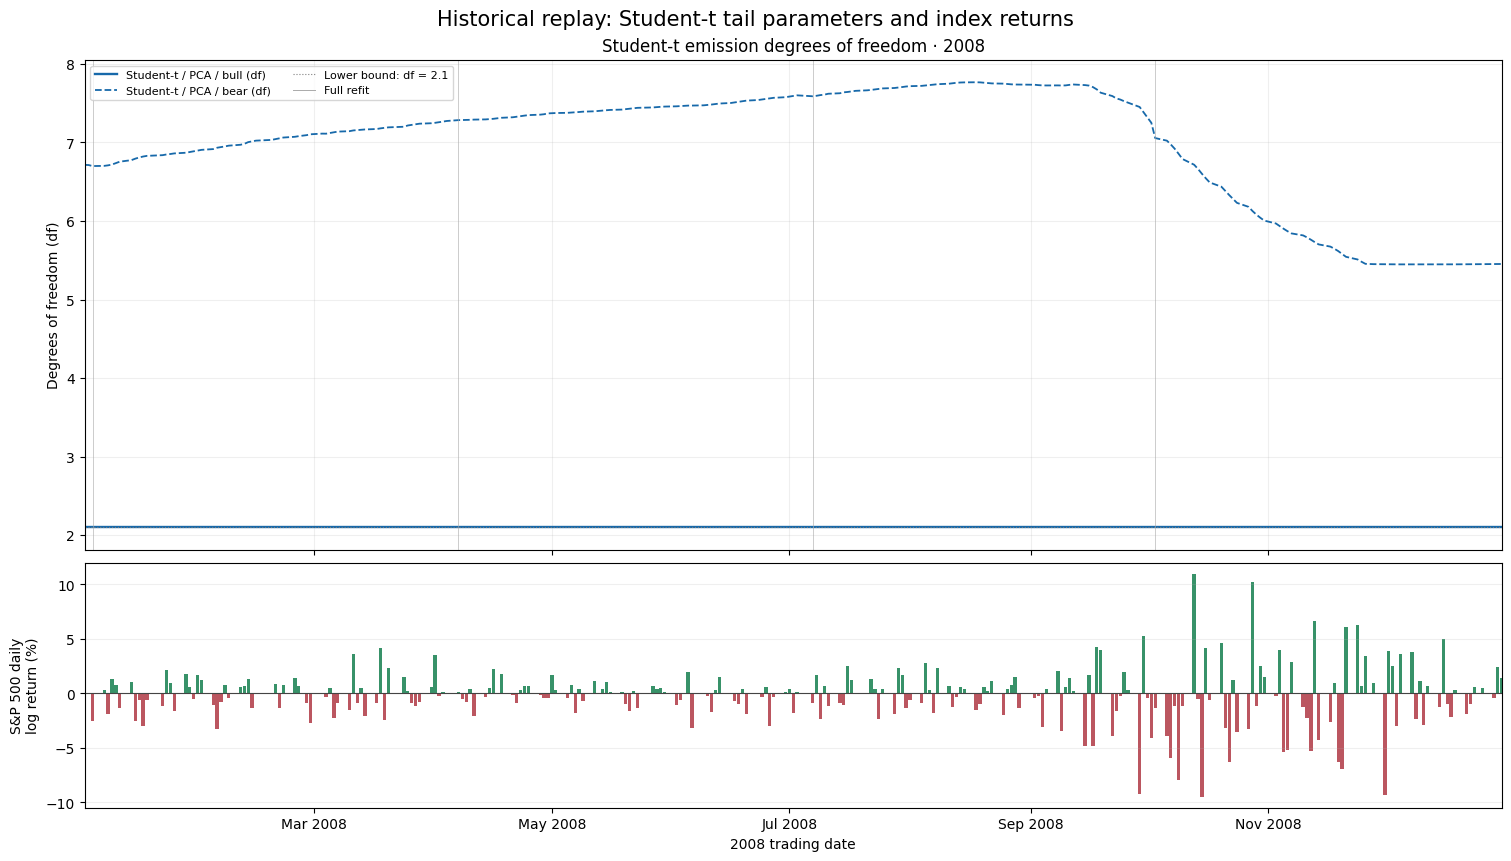

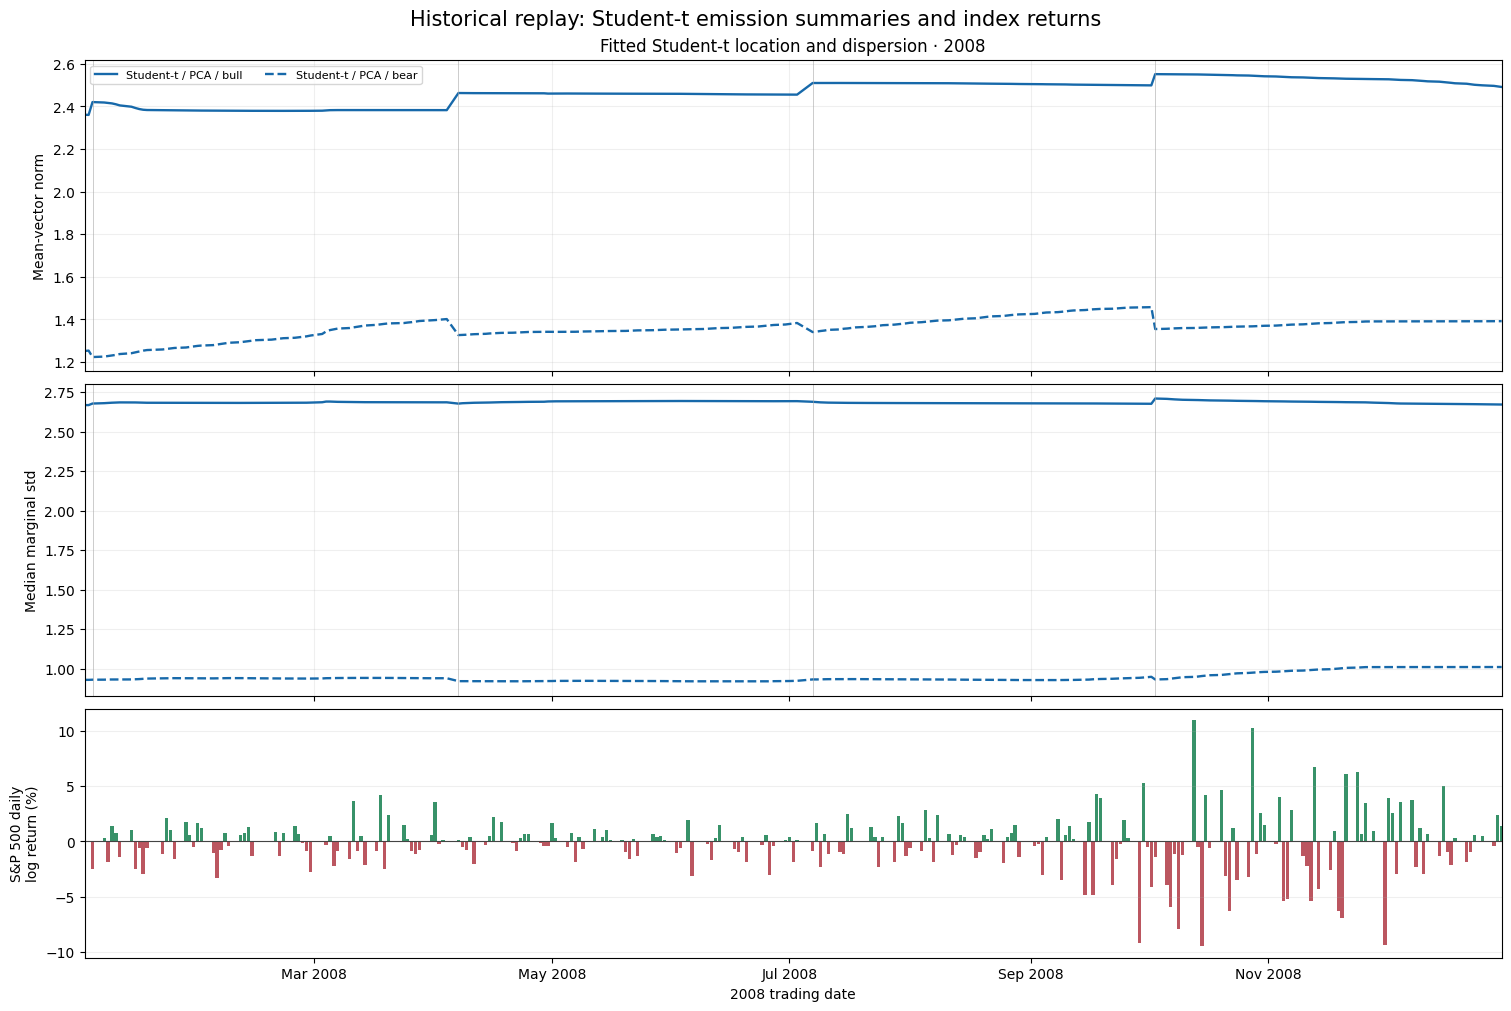

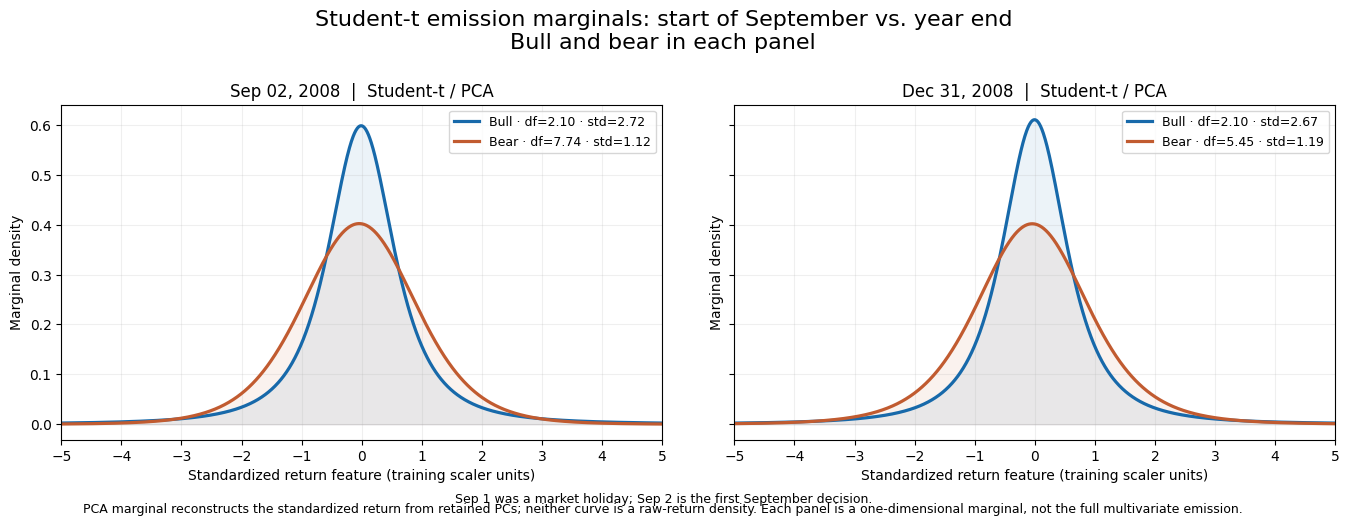

In [10]:
from plot_2008_student_t_emissions import COLORS, draw_figures, replay_emissions

# Replay both Student-t legs from the full merged signal rows; later cells
# select one leg. Forecasts are validated against every saved decision.
full_signals = pd.read_csv(RESULT_DIR / "signals.csv", parse_dates=["date"])
emission_daily, coordinate_parameters, return_marginals = replay_emissions(
    full_signals, prices
)
print(f"Validated {emission_daily.date.nunique()} 2008 trading dates; "
      f"maximum forecast difference: "
      f"{emission_daily.max_forecast_error.max():.3g}")
pca_daily = emission_daily.loc[emission_daily.branch.eq("Student-t / PCA")]
draw_figures(pca_daily, prices,
             colors={"Student-t / PCA": COLORS["Student-t / PCA"]})

# Single-row marginals for the PCA leg: Sep 2 (left) vs Dec 31 (right).
from plot_2008_student_t_emissions import draw_return_marginals
draw_return_marginals(return_marginals, branch="Student-t / PCA")

In [11]:
selected_dates = [
    "2008-10-03", "2008-11-26", "2008-11-28", "2008-12-01", "2008-12-31"
]
parameter_summary = pca_daily.loc[
    emission_daily.date.isin(pd.to_datetime(selected_dates))
]
assert len(parameter_summary) == len(selected_dates)
parameter_summary = pd.concat([
    parameter_summary[["date", "branch", "components", f"{state}_df",
                       f"{state}_mean_norm", f"{state}_median_std"]]
    .rename(columns={f"{state}_df": "Degrees of freedom",
                     f"{state}_mean_norm": "Mean-vector norm",
                     f"{state}_median_std": "Median marginal std"})
    .assign(State=state)
    for state in ("bull", "bear")
]).sort_values(["date", "branch", "State"])
display(parameter_summary.rename(columns={
    "date": "Decision date", "branch": "Student-t branch",
    "components": "Coordinates",
}).reset_index(drop=True).round(3))

,Decision date,Student-t branch,Coordinates,Degrees of freedom,Mean-vector norm,Median marginal std,State
0,2008-10-03,Student-t / PCA,11,7.056,1.355,0.932,bear
1,2008-10-03,Student-t / PCA,11,2.100,2.551,2.710,bull
2,2008-11-26,Student-t / PCA,11,5.455,1.391,1.010,bear
3,2008-11-26,Student-t / PCA,11,2.100,2.528,2.686,bull
4,2008-11-28,Student-t / PCA,11,5.451,1.391,1.011,bear
5,2008-11-28,Student-t / PCA,11,2.100,2.528,2.684,bull
6,2008-12-01,Student-t / PCA,11,5.450,1.391,1.011,bear
7,2008-12-01,Student-t / PCA,11,2.100,2.527,2.683,bull
8,2008-12-31,Student-t / PCA,11,5.453,1.392,1.011,bear
9,2008-12-31,Student-t / PCA,11,2.100,2.491,2.673,bull


## Gaussian, GMM, and Student-t emission marginals: September 2 and December 31, 2008

The replay helper refits Gaussian, GMM (M=2), and GMM (M=3) on the expanded history at each scheduled refresh, applies daily continuation updates, and validates every forecast against the merged signal rows. Each panel shows the **marginal density of the standardized return feature** projected from the retained principal components; it is not a raw-return density. Sep 1 was a market holiday.

The final display reuses the Student-t PCA marginals from the historical Student-t replay above, showing the same two dates. Each model is displayed separately at full size; no image files are written.


Gaussian/GMM replay maximum forecast difference: 8.33e-17


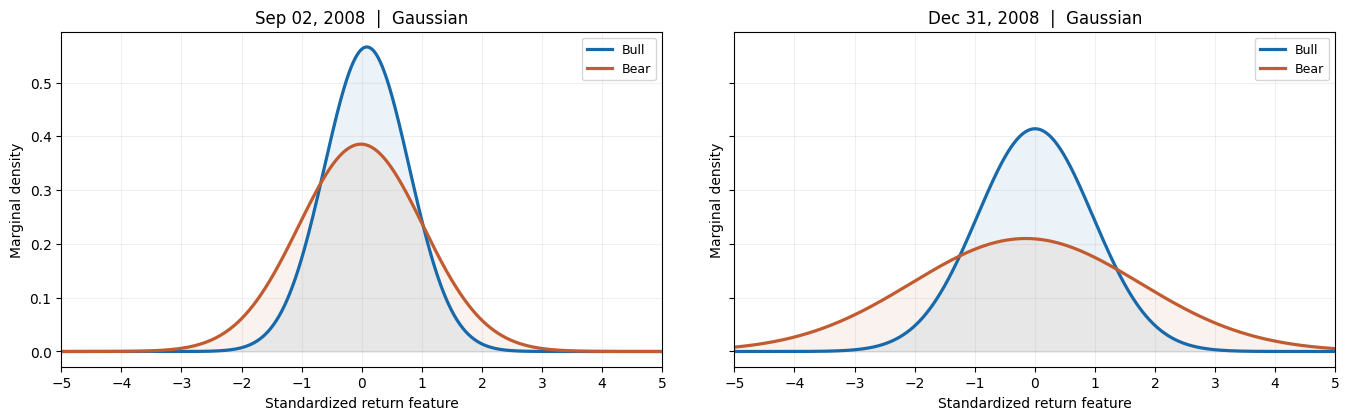

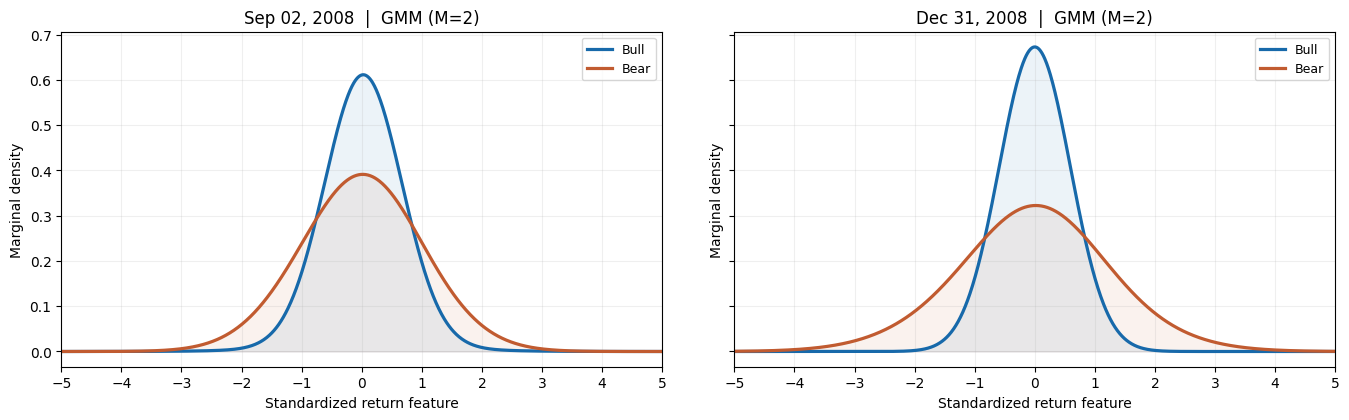

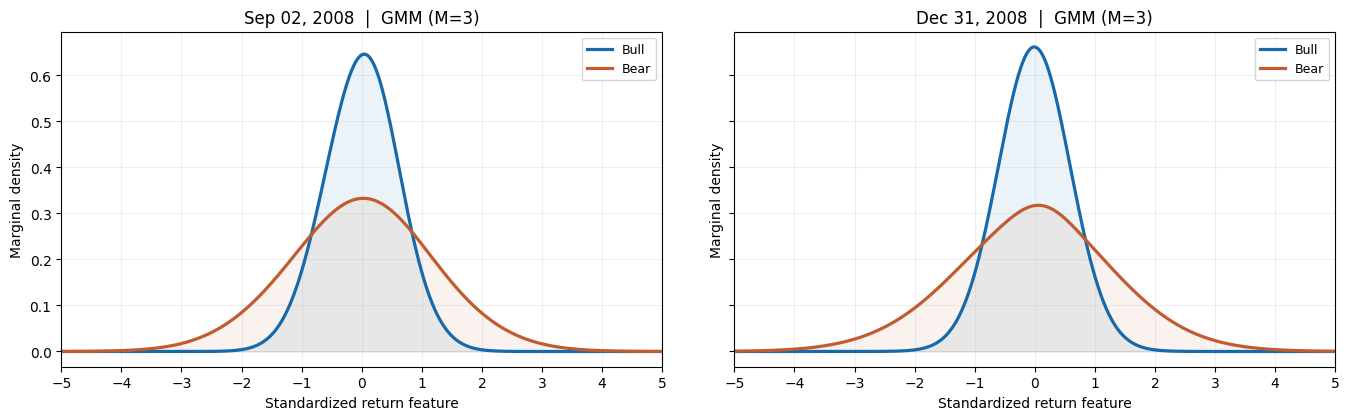

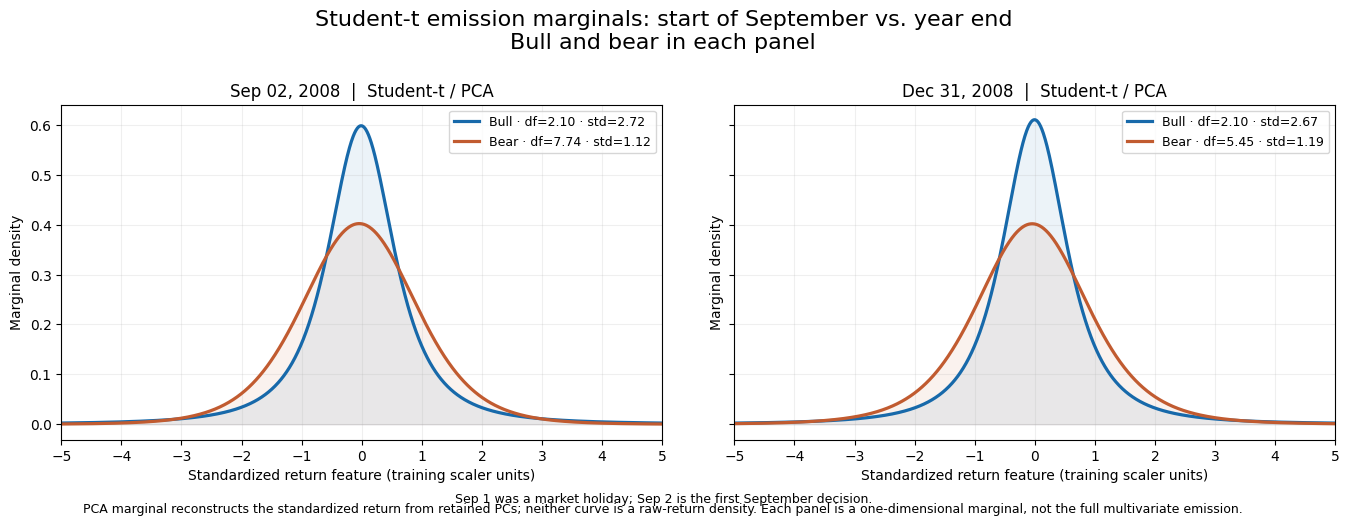

In [12]:
from plot_2008_gaussian_gmm_marginals import draw_marginals, replay_marginals

normal_marginals = replay_marginals(full_signals, prices)
print("Gaussian/GMM replay maximum forecast difference: "
      f"{normal_marginals.forecast_error.max():.3g}")
for family in ("Gaussian", "GMM (M=2)", "GMM (M=3)"):
    draw_marginals(normal_marginals, family, pca=True)

# Display the matching Student-t snapshots alongside the Gaussian/GMM outputs.
# Reuse the validated Student-t replay from the historical-emissions cell.
from plot_2008_student_t_emissions import draw_return_marginals

if "return_marginals" not in globals():
    raise RuntimeError("Run the historical Student-t emission replay cell first.")
draw_return_marginals(return_marginals, branch="Student-t / PCA")
